# Load profile from AIS data: Crown Seaways and Pearl Seaways
## Step 1: Loading and cleaning the data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

### Loading the data
We loaded the AIS data for both ferries in 2025 from a CSV file, and parsed `date_time_utc` as datetime.

In [2]:
aisdata = pd.read_csv('../data/ais_221026-ramleh.csv', parse_dates=['date_time_utc'])

aisdata.tail(10)

,date_time_utc,mmsi,dsrc,imo,ship_name,ship_type,callsign,maneuvre,lon,lat,...,rot,speed,cog,true_heading,length,breadth,draught,ais_class,geometry_wkt,date_utc
3134825,2025-12-30 21:36:05,219592000,G,8917613,NORDIC CROWN,60,OXRA6,0.0,10.694272,58.394080,...,-5.0,16.2,162.2,163.0,171,28,6.3,A,POINT(10.694272 58.39408),2025-12-30
3134826,2025-12-30 21:57:53,219592000,G,8917613,NORDIC CROWN,60,OXRA6,0.0,10.751060,58.301590,...,5.0,16.0,162.1,163.0,171,28,6.3,A,POINT(10.75106 58.30159),2025-12-30
3134827,2025-12-30 22:23:35,219592000,G,8917613,NORDIC CROWN,60,OXRA6,0.0,10.818136,58.191800,...,0.0,16.2,162.5,163.0,171,28,6.3,A,POINT(10.818136 58.1918),2025-12-30
3134828,2025-12-30 22:45:28,219945000,S,8701674,NORDIC PEARL,69,OWFU2,0.0,11.498333,57.406666,...,0.0,1.6,341.0,0.0,178,30,6.4,A,POINT(11.498333 57.406666),2025-12-30
3134829,2025-12-30 22:54:31,219945000,S,8701674,NORDIC PEARL,69,OWFU2,0.0,11.473333,57.443333,...,0.0,1.6,340.0,0.0,178,30,6.4,A,POINT(11.473333 57.443333),2025-12-30
3134830,2025-12-30 23:00:33,219945000,S,8701674,NORDIC PEARL,69,OWFU2,0.0,11.456667,57.468334,...,0.0,1.6,341.0,0.0,178,30,6.4,A,POINT(11.456667 57.468334),2025-12-30
3134831,2025-12-30 16:50:27,219945000,S,8701674,NORDIC PEARL,69,OWFU2,0.0,12.688334,55.991665,...,0.0,1.6,340.0,0.0,178,30,6.4,A,POINT(12.6883335 55.991665),2025-12-30
3134832,2025-12-30 05:21:43,219945000,S,8701674,NORDIC PEARL,69,OWFU2,0.0,12.275000,56.400000,...,0.0,1.5,165.0,0.0,178,30,6.4,A,POINT(12.275 56.4),2025-12-30
3134833,2025-12-30 05:27:43,219945000,S,8701674,NORDIC PEARL,69,OWFU2,0.0,12.283334,56.375000,...,0.0,1.5,173.0,0.0,178,30,6.4,A,POINT(12.283334 56.375),2025-12-30
3134834,2025-12-30 21:21:16,219945000,S,8701674,NORDIC PEARL,69,OWFU2,0.0,11.730000,57.046665,...,0.0,1.6,341.0,0.0,178,30,6.4,A,POINT(11.73 57.046665),2025-12-30


In [3]:
type(aisdata)

pandas.DataFrame

In [4]:
aisdata.shape

(3134835, 22)

In [5]:
aisdata.columns

Index(['date_time_utc', 'mmsi', 'dsrc', 'imo', 'ship_name', 'ship_type',
       'callsign', 'maneuvre', 'lon', 'lat', 'geom', 'status', 'rot', 'speed',
       'cog', 'true_heading', 'length', 'breadth', 'draught', 'ais_class',
       'geometry_wkt', 'date_utc'],
      dtype='str')

In [6]:
aisdata.info()

<class 'pandas.DataFrame'>
RangeIndex: 3134835 entries, 0 to 3134834
Data columns (total 22 columns):
 #   Column         Dtype         
---  ------         -----         
 0   date_time_utc  datetime64[us]
 1   mmsi           int64         
 2   dsrc           str           
 3   imo            int64         
 4   ship_name      str           
 5   ship_type      int64         
 6   callsign       str           
 7   maneuvre       float64       
 8   lon            float64       
 9   lat            float64       
 10  geom           str           
 11  status         int64         
 12  rot            float64       
 13  speed          float64       
 14  cog            float64       
 15  true_heading   float64       
 16  length         int64         
 17  breadth        int64         
 18  draught        float64       
 19  ais_class      str           
 20  geometry_wkt   str           
 21  date_utc       str           
dtypes: datetime64[us](1), float64(8), int64(6), str(7)
me

We used `describe()` to get summary statistics for each numeric column and to look for suspicious values.

In [7]:
aisdata.describe()

,date_time_utc,mmsi,imo,ship_type,maneuvre,lon,lat,status,rot,speed,cog,true_heading,length,breadth,draught
count,3134835,3.134835e+06,3.134835e+06,3.134835e+06,3128426.0,3.134835e+06,3.134835e+06,3.134835e+06,3.128426e+06,3.134835e+06,3.134835e+06,3.128426e+06,3.134835e+06,3.134835e+06,3.134835e+06
mean,2025-07-08 16:35:48.760744,2.197543e+08,8.818323e+06,6.556842e+01,0.0,1.073616e+01,5.897906e+01,6.629121e-02,2.577718e-02,1.502372e+01,2.265547e+02,2.295277e+02,1.742186e+02,2.891961e+01,6.310504e+00
min,2025-01-01 00:00:01,2.195920e+08,8.701674e+06,6.000000e+01,0.0,8.799155e+00,3.147591e+01,0.000000e+00,-1.280000e+02,0.000000e+00,0.000000e+00,0.000000e+00,1.710000e+02,2.800000e+01,6.100000e+00
25%,2025-04-18 16:38:35,2.195920e+08,8.701674e+06,6.000000e+01,0.0,1.060465e+01,5.851705e+01,0.000000e+00,-5.000000e+00,1.550000e+01,1.690000e+02,1.680000e+02,1.710000e+02,2.800000e+01,6.300000e+00
50%,2025-07-09 20:06:13,2.195920e+08,8.917613e+06,6.900000e+01,0.0,1.065362e+01,5.904863e+01,0.000000e+00,0.000000e+00,1.620000e+01,1.879000e+02,1.880000e+02,1.710000e+02,2.800000e+01,6.300000e+00
75%,2025-10-01 15:10:56.500000,2.199450e+08,8.917613e+06,6.900000e+01,0.0,1.074567e+01,5.956997e+01,0.000000e+00,5.000000e+00,1.670000e+01,3.465000e+02,3.450000e+02,1.780000e+02,3.000000e+01,6.300000e+00
max,2025-12-30 23:02:05,2.199450e+08,8.917613e+06,6.900000e+01,0.0,1.810000e+02,9.100000e+01,1.500000e+01,3.600000e+01,4.490000e+01,5.110000e+02,5.110000e+02,1.780000e+02,3.000000e+01,1.180000e+01
std,NaN,1.759288e+05,1.076201e+05,4.371325e+00,0.0,2.830574e-01,7.092139e-01,5.718780e-01,7.168174e+00,4.133920e+00,1.116438e+02,1.110884e+02,3.488673e+00,9.967637e-01,7.034450e-02


Number of data points for each ship (MMSI).

In [8]:
aisdata.mmsi.value_counts()

mmsi
219592000    1693422
219945000    1441413
Name: count, dtype: int64

**What we found in the dataset:**

- **Speed:** the max SOG was 44.9 kn, while the ferries normally sail at 16–18 kn.
- **Positions:** some rows had lat = 91 and lon = 181, which are AIS codes for "not available". The minimum latitude was 31.5, which is wrong since the ferries only sail Oslo–Copenhagen.
- **Course/heading:** valid values are 0–359°. In the AIS standard (ITU-R M.1371), `true_heading` = 511 and `cog` = 360 mean "not available". We also found `cog` = 511, which is not the standard code but equally invalid.
- **Odd single values:** `rot` = −128 means "not available", and a draught of 11.8 m was most likely an error.
- **Useless columns:** `maneuvre` was always 0, and `status` hardly ever changed, even when the ship was in port.
- **Missing values:** about 6,400 rows were missing `rot`, `true_heading` and `maneuvre`.
- **Two names per ship:** both ferries were renamed in 2025, so we used MMSI as the ID.
- **Not sorted:** the rows were not in time order.

### Cleaning the data

Before cleaning, we plotted the raw positions. The few invalid positions stretch the axes, so the actual route is squeezed into a small area to the left.

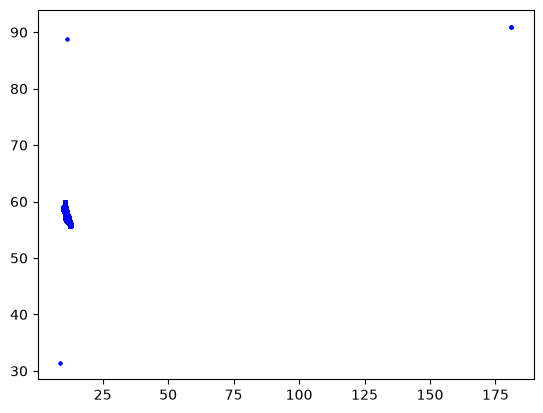

In [9]:
plt.scatter(aisdata["lon"], aisdata["lat"], s=5, color="blue")
plt.show()

We sorted the data by ship and time.

In [10]:
aisdata = aisdata.sort_values(['mmsi', 'date_time_utc'])
aisdata = aisdata.reset_index(drop=True)
aisdata.head()

,date_time_utc,mmsi,dsrc,imo,ship_name,ship_type,callsign,maneuvre,lon,lat,...,rot,speed,cog,true_heading,length,breadth,draught,ais_class,geometry_wkt,date_utc
0,2025-01-01 00:00:01,219592000,G,8917613,CROWN SEAWAYS,60,OXRA6,0.0,10.819025,58.400230,...,-9.0,16.9,155.6,158.0,171,28,6.2,A,POINT(10.819025 58.40023),2025-01-01
1,2025-01-01 00:00:06,219592000,G,8917613,CROWN SEAWAYS,60,OXRA6,0.0,10.819285,58.399872,...,-7.0,16.6,158.8,158.0,171,28,6.2,A,POINT(10.819285 58.39987166),2025-01-01
2,2025-01-01 00:00:18,219592000,G,8917613,CROWN SEAWAYS,60,OXRA6,0.0,10.819842,58.399158,...,-12.0,16.2,158.0,157.0,171,28,6.2,A,POINT(10.81984166 58.39915833),2025-01-01
3,2025-01-01 00:00:25,219592000,G,8917613,CROWN SEAWAYS,60,OXRA6,0.0,10.820135,58.398805,...,8.0,16.5,157.4,157.0,171,28,6.2,A,POINT(10.820135 58.398805),2025-01-01
4,2025-01-01 00:00:31,219592000,G,8917613,CROWN SEAWAYS,60,OXRA6,0.0,10.820700,58.398093,...,-5.0,16.9,158.3,157.0,171,28,6.2,A,POINT(10.8207 58.39809333),2025-01-01


We dropped columns we did not need: `maneuvre` is always 0, and `geom` / `geometry_wkt` only repeat `lon` and `lat`.

In [11]:
aisdata = aisdata.drop(columns=['maneuvre', 'geom', 'geometry_wkt'])
aisdata.columns

Index(['date_time_utc', 'mmsi', 'dsrc', 'imo', 'ship_name', 'ship_type',
       'callsign', 'lon', 'lat', 'status', 'rot', 'speed', 'cog',
       'true_heading', 'length', 'breadth', 'draught', 'ais_class',
       'date_utc'],
      dtype='str')

We removed duplicates with *df.drop_duplicates()*. A ship can only have one position at a given time, so we used `mmsi` and `date_time_utc` to identify duplicates.

In [12]:
aisdata = aisdata.drop_duplicates(subset=['mmsi', 'date_time_utc'], keep='last')
aisdata.shape

(3130528, 19)

We removed rows with missing values. These were the LRIT rows without `rot` and `true_heading`.

In [13]:
aisdata = aisdata.dropna()
aisdata.shape

(3126397, 19)

We removed positions outside the route Oslo–Copenhagen. This also removed lat = 91 and lon = 181, which mean "not available".

In [14]:
aisdata = aisdata[(aisdata['lat'] > 55) & (aisdata['lat'] < 60)]
aisdata = aisdata[(aisdata['lon'] > 9) & (aisdata['lon'] < 13)]
aisdata.shape

(3126393, 19)

We removed unrealistic speeds, since the ferries normally sail at 16–18 kn.

In [15]:
aisdata['speed'].describe()

count    3.126393e+06
mean     1.503427e+01
std      4.116405e+00
min      0.000000e+00
25%      1.550000e+01
50%      1.620000e+01
75%      1.670000e+01
max      4.490000e+01
Name: speed, dtype: float64

In [16]:
aisdata = aisdata[aisdata['speed'] < 25]
aisdata.shape

(3126391, 19)

We removed invalid course and heading values. Valid values are 0–359°, so 360 and 511 mean "not available".

In [17]:
aisdata = aisdata[aisdata['cog'] < 360]
aisdata = aisdata[aisdata['true_heading'] < 360]
aisdata.shape

(3126336, 19)

We removed `rot` = −128, which means "not available".

In [18]:
aisdata = aisdata[aisdata['rot'] != -128]
aisdata.shape

(3126335, 19)

We checked the draught values and removed the unrealistic value of 11.8 m.

In [19]:
aisdata['draught'].value_counts()

draught
6.3     1916550
6.4      641845
6.2      483081
6.5       84673
6.1         148
11.8         38
Name: count, dtype: int64

In [20]:
aisdata = aisdata[aisdata['draught'] < 8]
aisdata.shape

(3126297, 19)

In [21]:
aisdata.describe()

,date_time_utc,mmsi,imo,ship_type,lon,lat,status,rot,speed,cog,true_heading,length,breadth,draught
count,3126297,3.126297e+06,3.126297e+06,3.126297e+06,3.126297e+06,3.126297e+06,3.126297e+06,3.126297e+06,3.126297e+06,3.126297e+06,3.126297e+06,3.126297e+06,3.126297e+06,3.126297e+06
mean,2025-07-08 22:19:49.634794,2.197543e+08,8.818351e+06,6.556299e+01,1.073455e+01,5.898158e+01,6.300777e-02,2.705405e-02,1.503468e+01,2.265355e+02,2.295253e+02,1.742177e+02,2.891935e+01,6.310486e+00
min,2025-01-01 00:00:01,2.195920e+08,8.701674e+06,6.000000e+01,9.832545e+00,5.570167e+01,0.000000e+00,-3.800000e+01,0.000000e+00,0.000000e+00,0.000000e+00,1.710000e+02,2.800000e+01,6.100000e+00
25%,2025-04-18 21:25:01,2.195920e+08,8.701674e+06,6.000000e+01,1.060455e+01,5.851896e+01,0.000000e+00,-5.000000e+00,1.550000e+01,1.690000e+02,1.680000e+02,1.710000e+02,2.800000e+01,6.300000e+00
50%,2025-07-10 01:17:45,2.195920e+08,8.917613e+06,6.900000e+01,1.065340e+01,5.904965e+01,0.000000e+00,0.000000e+00,1.620000e+01,1.878000e+02,1.880000e+02,1.710000e+02,2.800000e+01,6.300000e+00
75%,2025-10-01 18:33:53,2.199450e+08,8.917613e+06,6.900000e+01,1.074552e+01,5.957022e+01,0.000000e+00,5.000000e+00,1.670000e+01,3.466000e+02,3.450000e+02,1.780000e+02,3.000000e+01,6.300000e+00
max,2025-12-30 23:02:05,2.199450e+08,8.917613e+06,6.900000e+01,1.283362e+01,5.990352e+01,1.500000e+01,3.600000e+01,2.430000e+01,3.599000e+02,3.590000e+02,1.780000e+02,3.000000e+01,6.500000e+00
std,NaN,1.759251e+05,1.076178e+05,4.372649e+00,2.435230e-01,7.036895e-01,5.577235e-01,7.152098e+00,4.115647e+00,1.116521e+02,1.110819e+02,3.488600e+00,9.967429e-01,6.762825e-02


After cleaning, we plotted the positions again. Now the route Oslo–Copenhagen is clearly visible.

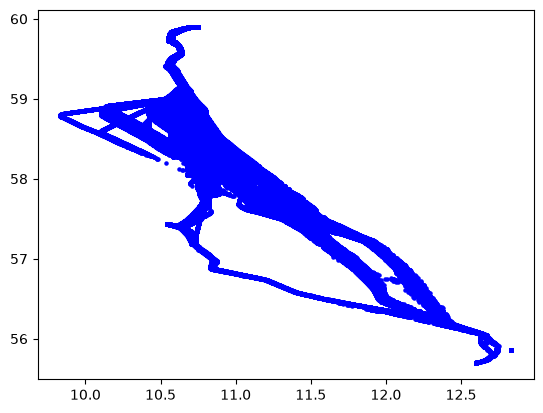

CPU times: user 639 ms, sys: 42.9 ms, total: 682 ms
Wall time: 753 ms


In [22]:
%%time
plt.scatter(aisdata["lon"], aisdata["lat"], s=5, color="blue")
plt.show()

### Visualizing the data on a map
We used *folium* to plot the positions on an interactive map.

In [30]:
import folium
from folium import plugins

The dataset has about 3 million points, which is too much for an interactive map, so we kept every 200th point.

In [31]:
AISmap = aisdata[['lat', 'lon']].iloc[::200]
AISmap.shape

(15632, 2)

We plotted each position as a blue point.

In [32]:
m2 = folium.Map(location=[57.8, 11.2], zoom_start=7)

In [33]:
AISmap.apply(lambda row:folium.CircleMarker(location=[row['lat'], row['lon']], 
                                              radius=1, fill_color='blue', color='blue')
                                             .add_to(m2), axis = 1)
m2

We also made a heatmap to show where the traffic is most dense.

In [27]:
mm = folium.Map(location=[57.8, 11.2], zoom_start=7)

In [28]:
mm.add_child(plugins.HeatMap(AISmap, radius=15))
mm